# Trabajo Práctico N° 3: SVM y Random Forest

| | |
|---|---|
| **Año** | 2026 |
| **Materia** | Minería de Datos, Tecnicatura Universitaria en Inteligencia Artificial |
| **Integrantes** | Josías Calabozo · Ismael Darruiz · Sebastián Di Carlo |

**Objetivo:** recomendar un cultivo (`clase`, 10 clases) a partir de 16 parámetros de suelo y clima (`crop_recommendation_geo.csv`), con los modelos de las unidades 5 y 6: SVM con kernel lineal, SVM con kernel gaussiano (RBF) y Random Forest.

**Contenido:** 1. Preparación de datos, 2. SVM con kernel lineal, 3. SVM con kernel gaussiano (RBF), 4. Random Forest, 5. Comparación de modelos y 6. Conclusiones.

Como pide la consigna, todos los modelos se evalúan con la misma validación cruzada estratificada de 5 folds sobre todo el conjunto limpio, con `random_state = 13`. Cuando reutilizamos o adaptamos código de los notebooks de clase, el comentario de la celda dice de cuál sale.

In [1]:
# Análisis exploratorio
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Preparación de los datos y validación cruzada
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Modelos
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

# random_state que pide la consigna para los modelos y la validación cruzada
SEMILLA = 13

# Ruta relativa a la carpeta del notebook (tp3/notebooks/)
RUTA_DATOS = "../data/crop_recommendation_geo.csv"

---
## 1. Preparación de datos

### 1.1 Estructura y valores faltantes

Las 16 variables predictoras, con la descripción de la consigna y las unidades de la página del dataset en Kaggle:

| Variable | Descripción | Unidad |
|---|---|---|
| `N` | Nitrógeno total en el suelo (0-30 cm) | g/kg |
| `P` | Fósforo disponible para las plantas (Olsen) | mg/kg |
| `exch_bases` | Bases intercambiables totales (Ca + Mg + K + Na), capa superficial del suelo: la medición de potasio | cmol(c)/kg |
| `ph` | pH del suelo en agua (0-30 cm) | sin unidad |
| `soc` | Carbono orgánico del suelo (0-30 cm) | g/kg |
| `arcilla` | Fracción arcillosa (0-30 cm) | % |
| `arena` | Fracción de arena (0-30 cm) | % |
| `cec` | Capacidad de intercambio catiónico | cmol(c)/kg |
| `temperatura` | Temperatura media anual del aire | °C |
| `temp_min_mensual` | Temperatura media del mes más frío | °C |
| `temp_max_mensual` | Temperatura media del mes más cálido | °C |
| `humedad` | Humedad relativa media anual | % |
| `lluvia` | Precipitación anual | mm/año |
| `estacionalidad_lluvias` | Coeficiente de variación de la precipitación mensual (BIO15) | % |
| `radiacion_solar` | Radiación solar incidente media anual | MJ/m²/día |
| `elevacion` | Altura sobre el nivel del mar | m |

In [2]:
# El archivo usa ";" como separador y coma decimal
datos = pd.read_csv(RUTA_DATOS, sep=";", decimal=",")
datos.head()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


In [3]:
# Tipo de cada columna y cantidad de valores no nulos
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

In [4]:
# Filas con algún valor faltante
datos[datos.isna().any(axis=1)]

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Hay 50004 muestras, con 16 variables predictoras numéricas y la variable objetivo `clase` como texto. Eliminamos la única fila con faltantes, la 25085 (`cafe`), a la que le faltan `ph`, `cec` y `humedad`: imputarla con la media o la mediana inventaría 3 de sus 16 valores para recuperar una sola fila de más de 50.000.

### 1.2 Registros duplicados

In [5]:
# keep=False marca todas las filas que tienen una copia; duplicated() marca solo las copias de más
print(f"Filas que tienen al menos una copia: {datos.duplicated(keep=False).sum()}")
print(f"Copias de más: {datos.duplicated().sum()}")

# Cultivo de las copias
datos[datos.duplicated()]["clase"].value_counts()

Filas que tienen al menos una copia: 396
Copias de más: 198


clase
lenteja     109
manzana      55
algodon      14
garbanzo     12
maiz          3
frijol        3
arroz         2
Name: count, dtype: int64

Eliminamos las 198 copias y nos quedamos con la primera aparición de cada fila. Cada fila repetida aparece exactamente dos veces, y casi todas las copias son de `lenteja` (109) y de `manzana` (55). Si quedaran, una copia podría caer en los folds de entrenamiento y la otra en el de evaluación, y el modelo se evaluaría con filas que ya vio; además, pesarían el doble en el entrenamiento.

### 1.3 Distribución de las variables predictoras

Esperamos colas largas hacia la derecha en las variables del suelo (`N`, `P`, `soc`, `exch_bases` y `cec`), la lluvia y la elevación, que tienen un piso cerca de cero pero no un techo, y distribuciones más simétricas en el resto, que tienen rangos acotados.

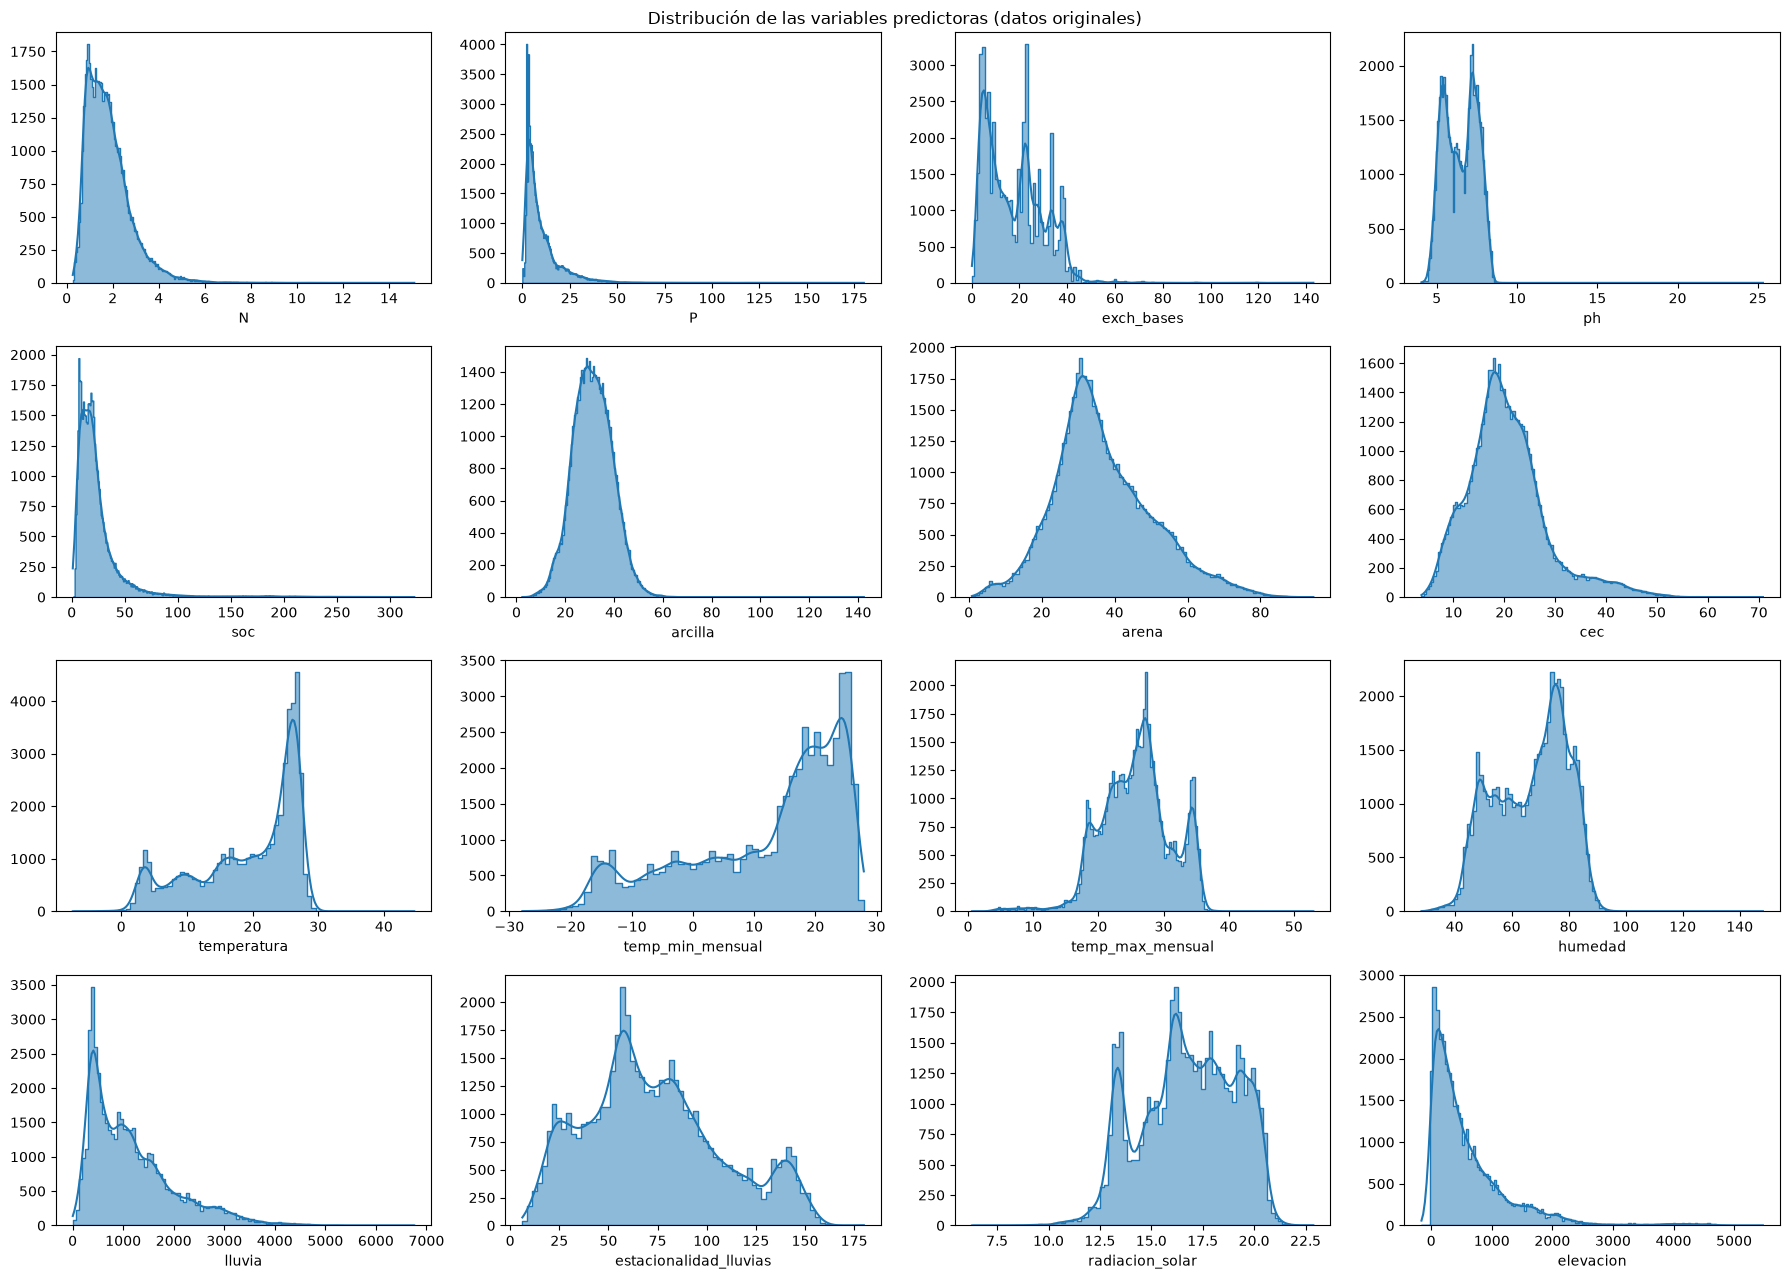

In [6]:
# Histograma de cada variable en una grilla de 4 × 4, como en U5_SVMClassifier_wine.ipynb (sección "Distribución
# de variables"), pero sin separar por clase: con 10 cultivos superpuestos no se leería
ATRIBUTOS = list(datos.columns.drop("clase"))   # las 16 variables predictoras
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, columna in zip(axes.flatten(), ATRIBUTOS):
    sns.histplot(data=datos, x=columna, kde=True, element="step", ax=ax)
    ax.set(ylabel="")
fig.suptitle("Distribución de las variables predictoras (datos originales)")
plt.tight_layout()
plt.show()

Se cumple en parte. `N`, `P`, `soc`, `lluvia` y `elevacion` tienen colas largas a la derecha, y `cec` también, aunque menos; `exch_bases` tiene varios picos. Pero las de rango acotado tampoco son simétricas: `ph` y `humedad` tienen dos picos (el pH, cerca de 5,5 y de 7), y `temperatura` y `temp_min_mensual` se acumulan en los valores altos, con una cola larga hacia el frío. Esos picos pueden ser grupos de cultivos; lo vemos por cultivo en 1.4.

Además, cinco ejes se estiran mucho más allá de los datos: `ph` llega a 25 (la escala va de 0 a 14), `arcilla` y `humedad` a 142 y 148 %, y `temperatura` y `temp_max_mensual` a 44 y 53 °C, cuando casi todos los valores están por debajo de 30 y de 40. Los revisamos en 1.4.

### 1.4 Valores atípicos

Contamos los atípicos de cada variable con la regla del rango intercuartílico, y con los diagramas de caja por cultivo vemos cuáles son errores y cuáles la cola de algún cultivo. Esperamos que la regla marque muchos en las variables con cola larga de 1.3, y que los errores sean pocos puntos aislados, lejos de los valores de su cultivo y a veces fuera del rango posible (el pH va de 0 a 14, y la humedad, la arcilla y la arena, de 0 a 100 %).

In [7]:
# Función de U3_Clustering.ipynb (sección "Remocion de Outliers"), la misma que usamos en el TP1 y el TP2:
# devuelve solo las filas que quedan dentro de los límites del rango intercuartílico
def remove_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]


# Adaptada del "Conteo de atípicos por columna" de U4_DecisionTreeRegresion.ipynb, como en el TP2: cuenta con
# remove_outliers_iqr y devuelve la tabla en lugar de imprimirla. Las filas con faltantes no se cuentan
def contar_atipicos(df, columnas):
    """Cantidad y porcentaje de atípicos de cada columna, según la regla del rango intercuartílico."""
    resultados = []
    for col in columnas:
        cantidad = df[col].notna().sum() - len(remove_outliers_iqr(df, col))
        resultados.append({"Variable": col, "Cantidad": cantidad, "Porcentaje": round(100 * cantidad / len(df), 1)})
    return pd.DataFrame(resultados)


contar_atipicos(datos, ATRIBUTOS)

,Variable,Cantidad,Porcentaje
0,N,1483,3.0
1,P,3453,6.9
2,exch_bases,181,0.4
3,ph,2,0.0
4,soc,3665,7.3
5,arcilla,292,0.6
6,arena,849,1.7
7,cec,2162,4.3
8,temperatura,14,0.0
9,temp_min_mensual,9,0.0


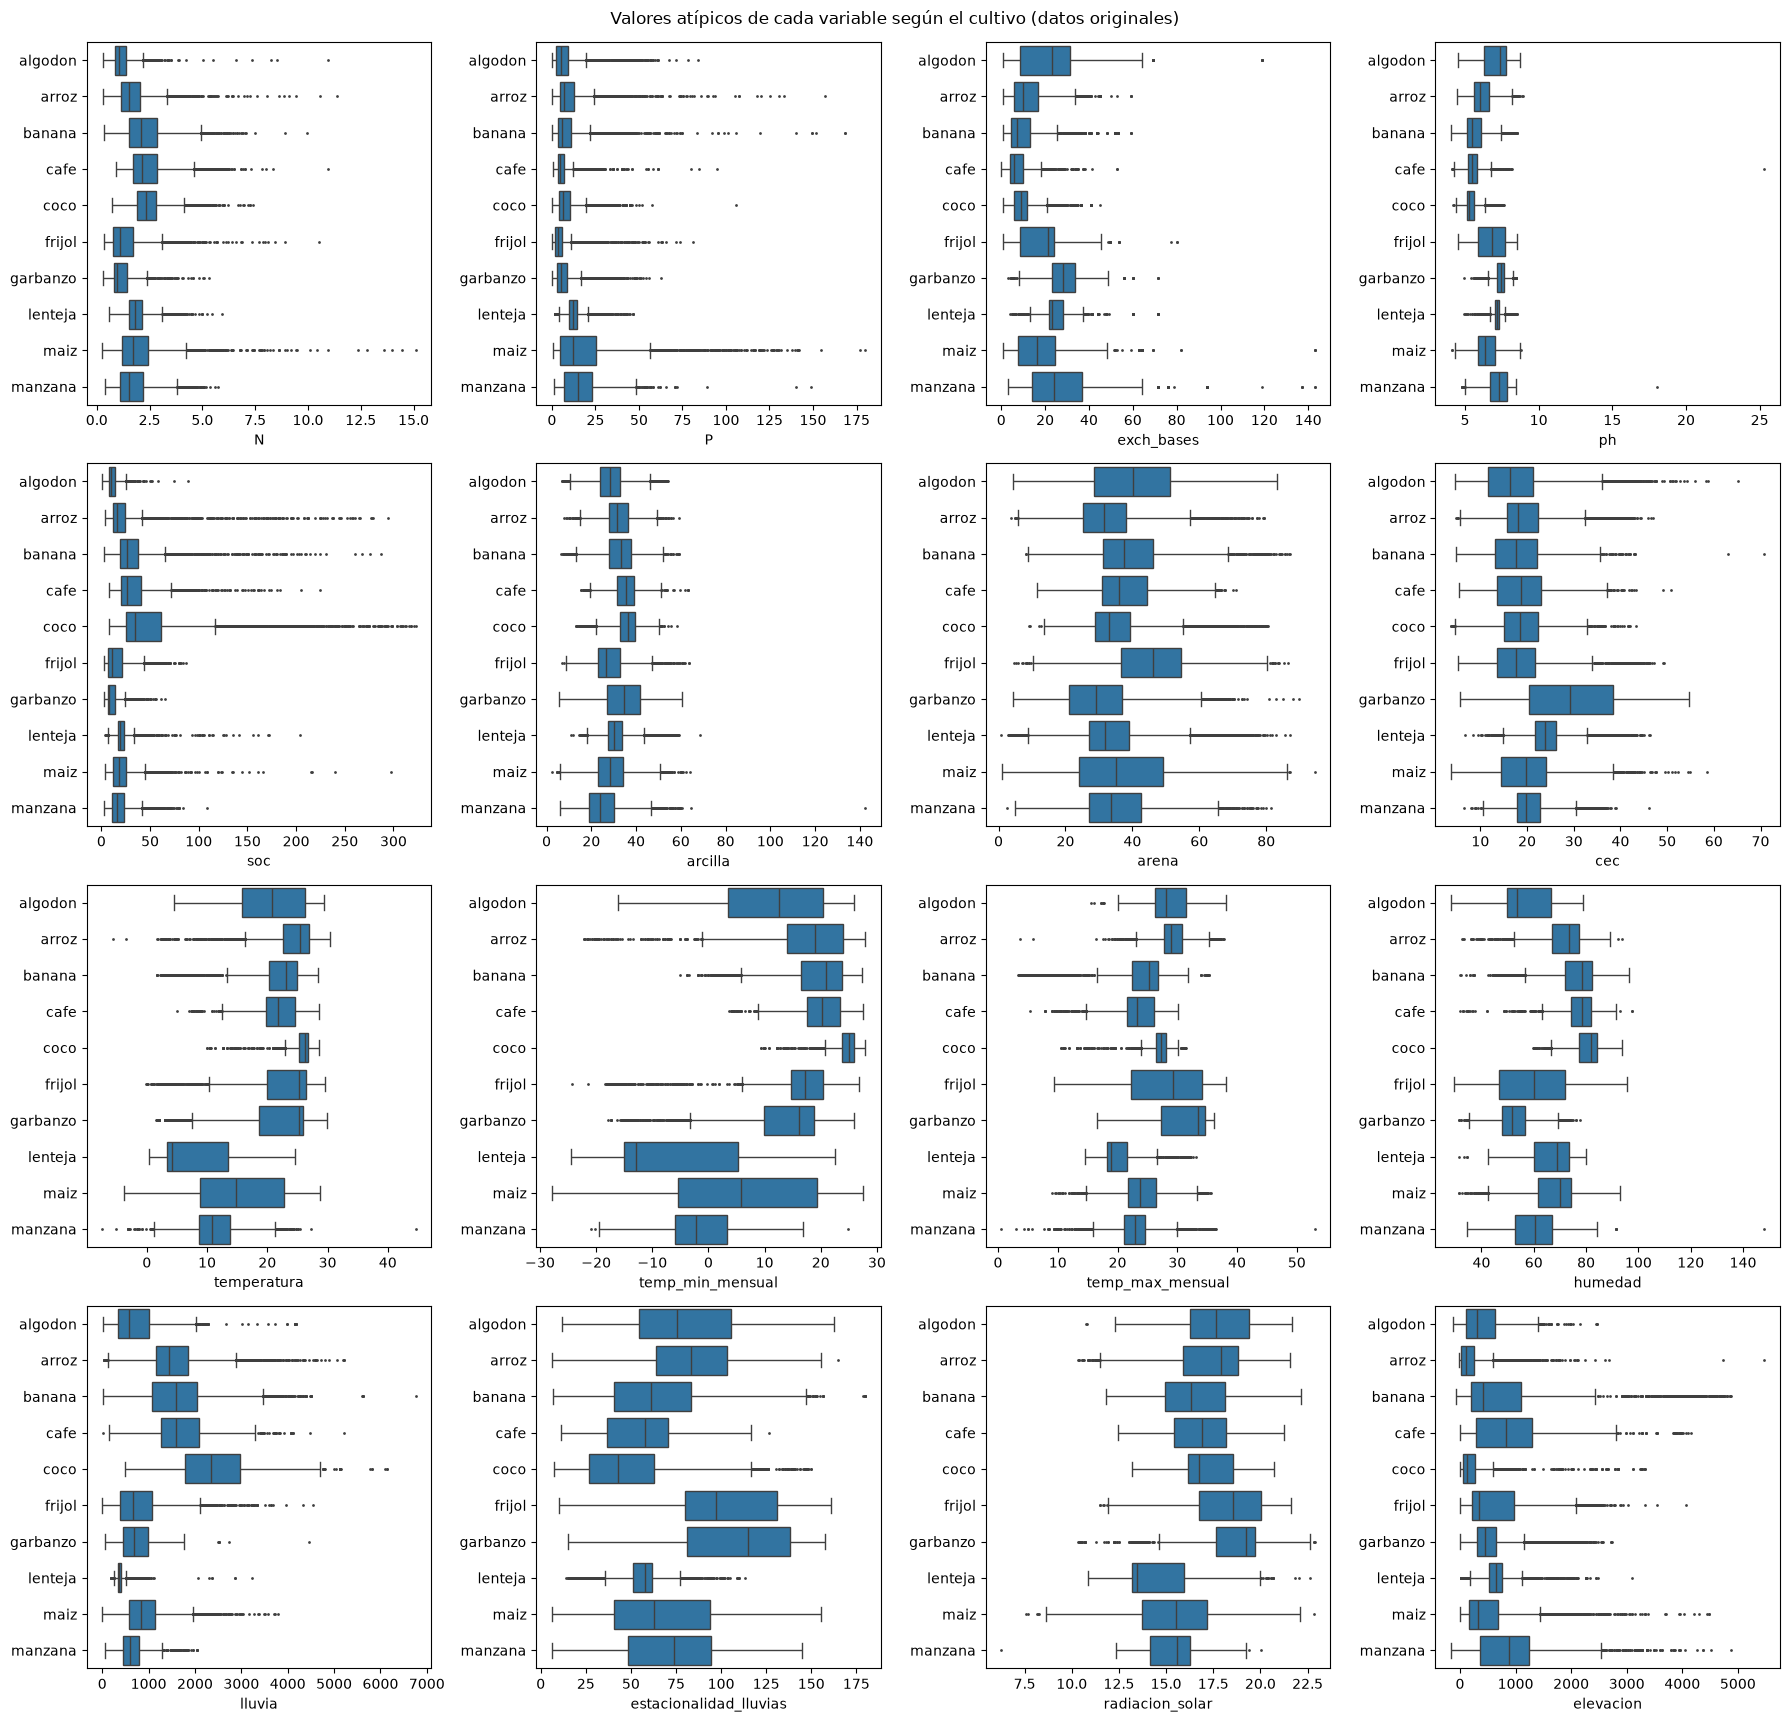

In [8]:
# Diagrama de caja de cada variable separado por cultivo, como el box plot por clase de RF_heartBinomial.ipynb (U6)
ORDEN_CLASES = sorted(datos["clase"].unique())
fig, axes = plt.subplots(4, 4, figsize=(18, 17))
for ax, columna in zip(axes.flatten(), ATRIBUTOS):
    sns.boxplot(data=datos, x=columna, y="clase", order=ORDEN_CLASES, fliersize=1, ax=ax)
    ax.set(ylabel="")
plt.tight_layout()
fig.suptitle("Valores atípicos de cada variable según el cultivo (datos originales)", y=1.01)
plt.show()

Se cumple, y solo eliminamos las filas con valores imposibles: los atípicos que marca la regla se quedan. La regla marca muchos en las variables con cola larga (3665 en `soc`, el 7,3 %; 3453 en `P`, el 6,9 %; 2825 en `elevacion`, el 5,6 %; 2162 en `cec` y 1483 en `N`), pero en los diagramas de caja son colas continuas y propias de algunos cultivos: los valores altos de `P` son sobre todo de `maiz` y `arroz`; los de `soc`, de `coco`, `arroz` y `banana`; y los de `elevacion`, de `banana`, `cafe` y `manzana`. Son valores posibles, y sacarlos borraría parte de lo que distingue a esos cultivos. Además, el SVM es robusto ante valores atípicos, porque se apoya en los vectores soporte (apunte de la Unidad 5, «Ventajas de SVM»).

Los errores son unos pocos puntos aislados, muy lejos de los demás valores de su cultivo: dos en `ph` (uno de `cafe` y otro de `manzana`) y uno en cada una de `arcilla`, `humedad`, `temperatura`, `temp_max_mensual` y `radiacion_solar`, todos de `manzana`. Abajo los buscamos con los rangos posibles.

Los diagramas muestran también cómo cambia cada variable entre cultivos. Ninguna separa sola a los 10, pero varias separan grupos: con las temperaturas, `lenteja`, `manzana` y `maiz` son los de clima más frío, y `coco` el más cálido y con menos variación; con el pH, `algodon`, `garbanzo`, `lenteja` y `manzana` están en suelos neutros, cerca de 7, y `banana`, `cafe` y `coco` en suelos ácidos, cerca de 5,5. `banana` y `cafe` se parecen en casi todas las variables, y `maiz` es el cultivo con los rangos más amplios.

In [9]:
# Filas con valores imposibles: pH mayor a 14, o humedad relativa, arcilla o arena por encima del 100 %
fuera_de_rango = datos[(datos["ph"] > 14) | (datos["humedad"] > 100) | (datos["arcilla"] > 100)
                       | (datos["arena"] > 100)]
fuera_de_rango

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Son dos filas, y las eliminamos como errores de carga. La 25111 (`cafe`) tiene un pH de 25,3. La 30012 (`manzana`) tiene seis valores imposibles o aislados a la vez: pH de 18, arcilla de 142 %, humedad de 148 %, temperatura media de 44,6 °C, media del mes más cálido de 53 °C y radiación solar de 6,27 MJ/m²/día (los puntos aislados de los diagramas de caja). No las corregimos con la mediana: en la 30012 habría que reemplazar más de un tercio de la fila, y si una fila tiene un valor imposible, sus otros valores tampoco son confiables.

### 1.5 Limpieza

In [10]:
# Sacamos la fila con faltantes, las copias de las filas duplicadas y las filas con valores fuera de rango
datos_limpios = datos.dropna()
datos_limpios = datos_limpios.drop_duplicates()
datos_limpios = datos_limpios.drop(fuera_de_rango.index)
print(f"Quedan {len(datos_limpios)} de {len(datos)} filas")
datos_limpios.describe().round(2)

Quedan 49803 de 50004 filas


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
count,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00,49803.00
mean,1.81,10.30,17.83,6.47,24.36,31.24,36.92,20.45,19.28,11.98,25.83,66.84,1158.18,72.89,16.78,599.35
std,0.96,11.13,11.98,1.01,26.51,8.03,13.57,7.75,7.69,12.59,5.24,12.58,833.11,34.75,2.27,660.77
min,0.26,0.00,1.00,4.05,1.02,2.40,0.88,3.72,-7.38,-27.87,0.58,28.37,3.00,6.20,7.58,-161.00
25%,1.10,3.68,7.00,5.55,11.02,25.62,28.03,15.52,14.30,3.24,22.26,56.03,486.00,48.08,15.14,158.00
50%,1.63,6.65,16.00,6.50,18.12,31.05,34.72,19.53,22.02,16.50,26.02,69.35,954.00,68.45,16.83,384.00
75%,2.27,12.84,26.50,7.35,27.23,36.77,45.07,24.20,25.79,22.12,28.99,76.98,1574.00,94.11,18.62,811.00
max,15.10,180.00,143.00,8.95,322.82,68.63,94.50,70.82,30.38,27.92,38.22,97.37,6759.00,179.91,22.88,5476.00


Quedan 49803 filas: sacamos 201 (la fila con faltantes, las 198 copias y las 2 filas con valores imposibles). Los máximos quedan en línea con el resto de cada distribución (`ph` llega a 8,95, `arcilla` a 68,63, `humedad` a 97,37, `temperatura` a 30,38 y `temp_max_mensual` a 38,22) y el mínimo de `radiacion_solar` sube a 7,58. El mínimo de `exch_bases` pasa a 1: el 0,1 de la fila 25111 era el único valor por debajo de 1, otra señal de que esa fila estaba mal cargada.

### 1.6 Distribución de clases

In [11]:
# Cantidad y porcentaje de muestras de cada cultivo, como target_balance de los notebooks de la U4 y la U5
pd.DataFrame({"Cantidad": datos_limpios["clase"].value_counts(),
              "Porcentaje": (datos_limpios["clase"].value_counts(normalize=True) * 100).round(2)})

,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Las clases quedan casi balanceadas, de 4891 muestras (`lenteja`, 9,82 %) a 5000 (`banana`, `cafe` y `coco`, 10,04 %): es el leve desbalance que menciona la consigna. `lenteja` y `manzana`, las dos clases con más copias en 1.2, son las que quedan con menos muestras.

### 1.7 Correlaciones

Buscamos variables que repitan la información de otra. Esperamos correlaciones fuertes entre las tres temperaturas y entre la humedad y la lluvia, y negativas entre arcilla y arena, que se reparten el mismo suelo, y entre la elevación y las temperaturas, porque en altura hace más frío.

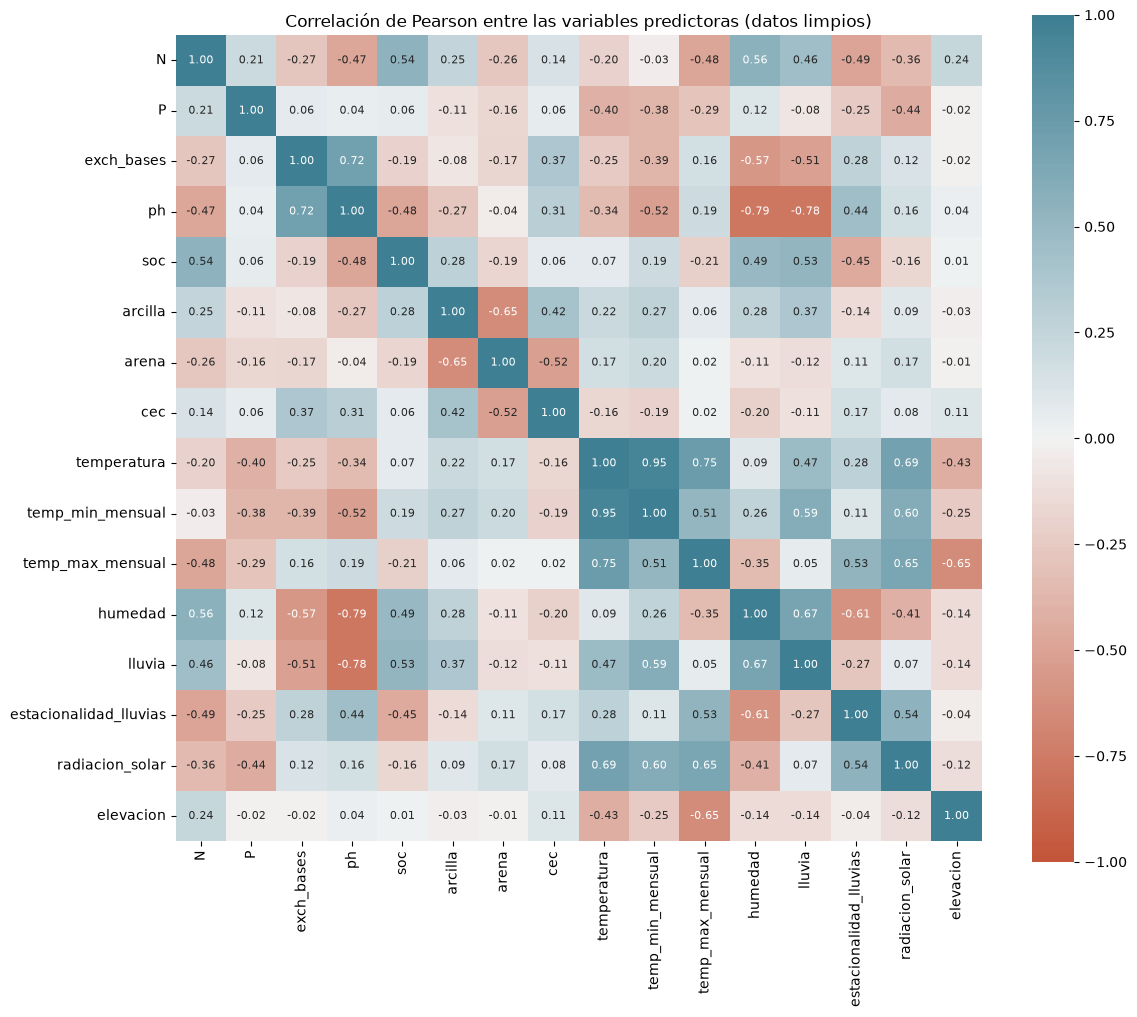

In [12]:
# Matriz de correlación de Pearson, con el mapa de calor de U5_SVMClassifier_wine.ipynb
correlaciones = datos_limpios[ATRIBUTOS].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(correlaciones, vmin=-1, vmax=1, center=0, cmap=sns.diverging_palette(20, 220, n=200),
            annot=True, fmt=".2f", annot_kws={"size": 8}, square=True)
plt.title("Correlación de Pearson entre las variables predictoras (datos limpios)")
plt.show()

Se cumple. La correlación más alta es la de `temperatura` con `temp_min_mensual` (0,95), y con `temp_max_mensual` es de 0,75; `humedad` y `lluvia` tienen 0,67, y `arcilla` y `arena`, −0,65. La elevación tiene −0,65 con `temp_max_mensual`, pero solo −0,43 con la temperatura media. Lo que no esperábamos es la relación del pH con el clima: baja con la humedad (−0,79) y con la lluvia (−0,78), es decir, los suelos de los lugares más húmedos y lluviosos son más ácidos, y sube con las bases intercambiables (0,72).

Salvo `temperatura` y `temp_min_mensual` (0,95), ningún par está tan correlacionado como para que una variable repita a la otra. Conservamos las 16 variables que plantea la consigna.

### 1.8 Codificación, estandarización y folds

In [13]:
# LabelEncoder, como pide la consigna: cada cultivo pasa a un número de 0 a 9, en orden alfabético
codificador = LabelEncoder()
y = codificador.fit_transform(datos_limpios["clase"])
X = datos_limpios[ATRIBUTOS]
pd.DataFrame({"Cultivo": codificador.classes_}).rename_axis("Código").T

Código,0,1,2,3,4,5,6,7,8,9
Cultivo,algodon,arroz,banana,cafe,coco,frijol,garbanzo,lenteja,maiz,manzana


In [14]:
# Los 5 folds estratificados que usan todos los modelos. El archivo viene ordenado por cultivo: shuffle=True mezcla
# las filas antes de repartirlas, y es lo que hace que random_state tenga efecto
FOLDS = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Muestras de cada cultivo en cada fold
conteos = {}
for numero, (indices_train, indices_test) in enumerate(FOLDS.split(X, y), start=1):
    conteos[f"Fold {numero}"] = pd.Series(codificador.classes_[y[indices_test]]).value_counts()
conteos = pd.DataFrame(conteos)
conteos.loc["Total"] = conteos.sum()
conteos

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
algodon,997,997,997,997,998
arroz,1000,1000,1000,1000,999
banana,1000,1000,1000,1000,1000
cafe,1000,1000,1000,1000,1000
coco,1000,1000,1000,1000,1000
frijol,1000,1000,999,999,999
garbanzo,997,998,998,998,997
lenteja,978,978,979,978,978
maiz,1000,999,999,999,1000
manzana,989,989,989,989,989


Cada fold tiene 9960 o 9961 filas, con entre 978 y 1000 de cada cultivo: la estratificación mantiene las proporciones de 1.6. Los tres modelos usan estos mismos folds.

In [15]:
# Cada modelo es un pipeline que estandariza y después clasifica, como el make_pipeline de Unidad4.py
def crear_modelo(clasificador):
    """Pipeline que estandariza los 16 atributos con StandardScaler y después aplica el clasificador."""
    return make_pipeline(StandardScaler(), clasificador)


# Así quedan los atributos del entrenamiento del primer fold después de estandarizar
indices_train, indices_test = next(FOLDS.split(X, y))
escalador = StandardScaler().set_output(transform="pandas")
escalador.fit_transform(X.iloc[indices_train]).describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
N,0.0,1.0,-1.58,13.82
P,0.0,1.0,-0.93,15.32
exch_bases,0.0,1.0,-1.41,10.43
ph,-0.0,1.0,-2.39,2.44
soc,0.0,1.0,-0.88,11.25
arcilla,0.0,1.0,-3.59,4.16
arena,0.0,1.0,-2.63,4.25
cec,0.0,1.0,-2.16,5.79
temperatura,0.0,1.0,-3.47,1.38
temp_min_mensual,0.0,1.0,-3.17,1.26


La estandarización va dentro de cada modelo, así el escalador se ajusta solo con los 4 folds de entrenamiento de cada vuelta (apunte de la Unidad 4, «Estandarización vs Separación de datos»). En el entrenamiento del fold 1 todas las variables quedan con media 0 y desvío 1, y las colas largas de 1.3 se ven en los máximos: `P` llega a 15,32 desvíos, `N` a 13,82 y `soc` a 11,25, mientras que `ph` y `humedad` no pasan de 2,5.

---
## 2. SVM con kernel lineal

### 2.1 Búsqueda del parámetro C

Esperamos que la exactitud suba con C hasta estabilizarse, y que el SVM lineal confunda los cultivos que en 1.4 se superponen en casi todas las variables, como `banana` y `cafe`. También esperamos tiempos largos: según el apunte de la Unidad 5 («SVM: Costo Computacional y el parámetro C»), lo que más pesa en el tiempo de un SVM es la cantidad de observaciones, y cada entrenamiento usa unas 40.000.

Probamos 6 valores de C, de 0,001 a 100 en escala logarítmica: los 5 del ejemplo de la consigna y 0,001. Con 5 folds son 6 × 5 = 30 entrenamientos. Antes de ver los resultados fijamos el criterio para elegir, el mismo en los tres modelos: la mayor exactitud media en los 5 folds, porque con las clases casi balanceadas (1.6) pesa a todos los cultivos casi por igual.

In [16]:
# Las tres métricas que pide la consigna, con promedio weighted en la precisión y la exhaustividad, como
# pd_metricas_clasifier de gas_detection.ipynb (U6)
METRICAS = {"Precisión": "precision_weighted", "Exhaustividad": "recall_weighted", "Exactitud": "accuracy"}


# GridSearchCV como en U5_SVMClassifier_wine.ipynb (sección "Optimización del modelo"), con los 5 folds de 1.8, las
# tres métricas y n_jobs=-1 para entrenar en paralelo, como en Unidad5.py. refit=False: solo evalúa, no reentrena
# la mejor combinación con todos los datos
def buscar_hiperparametros(clasificador, grilla):
    """Evalúa cada combinación de la grilla en los 5 folds y devuelve la tabla de resultados de GridSearchCV."""
    busqueda = GridSearchCV(crear_modelo(clasificador), grilla, cv=FOLDS, scoring=METRICAS, refit=False, n_jobs=-1)
    busqueda.fit(X, y)
    return pd.DataFrame(busqueda.cv_results_)


def tabla_resultados(resultados, hiperparametros):
    """Media y desvío de cada métrica en los 5 folds, y tiempo medio de entrenamiento, de cada combinación."""
    tabla = pd.DataFrame()
    for parametro, nombre in hiperparametros.items():
        tabla[nombre] = resultados[f"param_{parametro}"]
    for metrica in METRICAS:
        tabla[f"{metrica} media"] = resultados[f"mean_test_{metrica}"].round(4)
        tabla[f"{metrica} desvío"] = resultados[f"std_test_{metrica}"].round(4)
    tabla["Entrenamiento por fold (s)"] = resultados["mean_fit_time"].round(1)
    return tabla


def mejor_configuracion(resultados):
    """Fila de la combinación con mayor exactitud media en los 5 folds (la primera, si hay empate)."""
    return resultados.loc[resultados["mean_test_Exactitud"].idxmax()]

In [17]:
# En el pipeline, cada hiperparámetro lleva adelante el nombre de su paso: svc__C es el C del paso svc.
# random_state no cambia nada en un SVC (solo se usa con probability=True), pero lo fijamos como pide la consigna
GRILLA_LINEAL = {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}
resultados_lineal = buscar_hiperparametros(SVC(kernel="linear", random_state=SEMILLA), GRILLA_LINEAL)
tabla_lineal = tabla_resultados(resultados_lineal, {"svc__C": "C"})
tabla_lineal

,C,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
0,0.001,0.5670,0.0039,0.5657,0.0035,0.5657,0.0035,69.1
1,0.010,0.6048,0.0044,0.6048,0.0036,0.6048,0.0036,51.0
2,0.100,0.6172,0.0056,0.6179,0.0050,0.6179,0.0050,50.3
3,1.000,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,83.9
4,10.000,0.6230,0.0049,0.6230,0.0047,0.6230,0.0047,215.2
5,100.000,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,860.9


Las columnas de exhaustividad y de exactitud son iguales, y lo van a ser en todos los modelos: la exhaustividad weighted pesa la de cada cultivo por su cantidad de muestras, y esa cuenta da la proporción total de aciertos. La precisión weighted queda muy cerca. Por eso, en los gráficos usamos solo la exactitud.

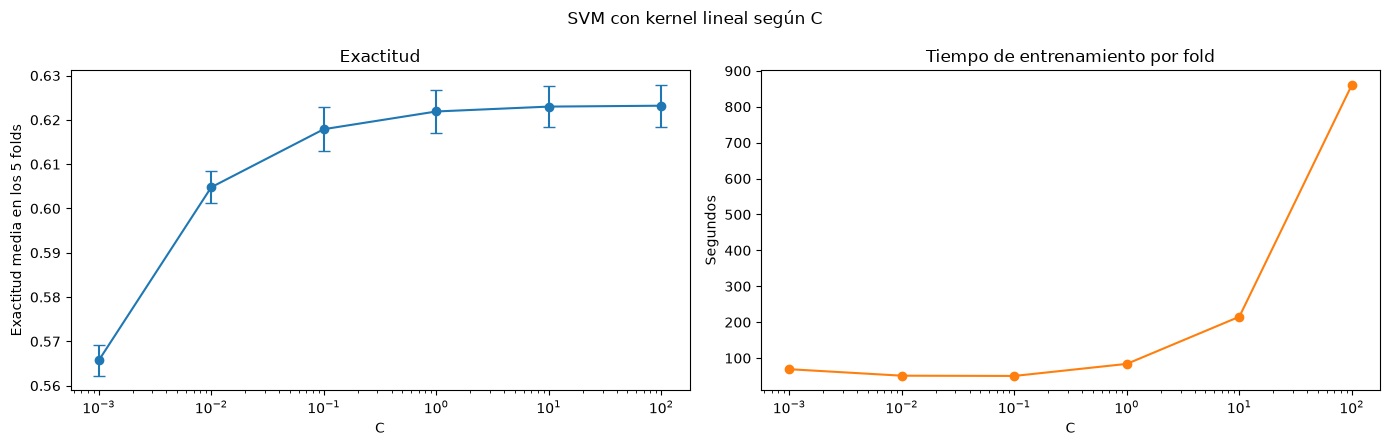

In [18]:
# Exactitud media con el desvío entre folds como barra de error, y tiempo de entrenamiento, según C
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].errorbar(tabla_lineal["C"], tabla_lineal["Exactitud media"], yerr=tabla_lineal["Exactitud desvío"],
                 marker="o", capsize=4)
axes[0].set(xscale="log", xlabel="C", ylabel="Exactitud media en los 5 folds", title="Exactitud")
axes[1].plot(tabla_lineal["C"], tabla_lineal["Entrenamiento por fold (s)"], marker="o", color="tab:orange")
axes[1].set(xscale="log", xlabel="C", ylabel="Segundos", title="Tiempo de entrenamiento por fold")
fig.suptitle("SVM con kernel lineal según C")
plt.tight_layout()
plt.show()

Se cumple. La exactitud sube de 0,5657 con C = 0,001 a 0,6219 con C = 1, y desde ahí casi no cambia (0,6230 con C = 10 y 0,6232 con C = 100), con diferencias mucho menores que el desvío entre folds, de alrededor de 0,005. Los tiempos son largos: entre 50 y 84 segundos por fold hasta C = 1, y después se disparan, a 215 con C = 10 y 861 con C = 100, unas diez veces más que con C = 1 sin ganar exactitud. Con un C grande el modelo busca no clasificar mal ningún dato (apunte de la Unidad 5, «SVM: Margen blando»), y como los cultivos se superponen, ningún hiperplano lo logra: el entrenamiento tarda mucho más y la exactitud no mejora.

Lo que no esperábamos es que se estanque tan abajo: el SVM lineal acierta el cultivo en 6 de cada 10 filas. Con 10 cultivos que se superponen en varias variables, los hiperplanos no alcanzan para separarlos.

### 2.2 Mejor configuración

In [19]:
mejor_lineal = mejor_configuracion(resultados_lineal)
tabla_lineal.loc[[mejor_lineal.name]]

,C,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
5,100.0,0.6232,0.005,0.6232,0.0047,0.6232,0.0047,860.9


Elegimos **C = 100**, la de mayor exactitud media (0,6232, con un desvío de 0,0047). La elección no es firme: le gana a C = 10 por 0,0002 y a C = 1 por 0,0013, mucho menos que el desvío entre folds, así que en la práctica los tres rinden lo mismo, y C = 100 es el que más tarda.

---
## 3. SVM con kernel gaussiano (RBF)

### 3.1 Búsqueda de C y gamma

Esperamos que el RBF supere al lineal, porque puede armar fronteras curvas, sobre todo en los cultivos que se superponen. Para gamma esperamos un máximo en valores intermedios, y que el mejor C dependa de gamma.

Probamos 5 valores de C (de 0,1 a 1000) y 5 de gamma (de 0,001 a 10): los 4 del ejemplo de la consigna para cada uno, más C = 1000 y gamma = 10, para comprobar que el máximo no quede en un borde de la grilla. Son 25 combinaciones × 5 folds = 125 entrenamientos. El mapa de calor muestra la interacción entre C y gamma que pide la consigna, junto con el tiempo de cada combinación.

In [20]:
GRILLA_RBF = {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": [0.001, 0.01, 0.1, 1, 10]}
resultados_rbf = buscar_hiperparametros(SVC(kernel="rbf", random_state=SEMILLA), GRILLA_RBF)
tabla_rbf = tabla_resultados(resultados_rbf, {"svc__C": "C", "svc__gamma": "gamma"})

# Ordenada de mayor a menor exactitud media
tabla_rbf.sort_values("Exactitud media", ascending=False)

,C,gamma,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
13,10.0,1.000,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,93.2
17,100.0,0.100,0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,36.9
8,1.0,1.000,0.8834,0.0029,0.8812,0.0029,0.8812,0.0029,85.7
18,100.0,1.000,0.8826,0.0023,0.8805,0.0027,0.8805,0.0027,86.7
23,1000.0,1.000,0.8804,0.0025,0.8783,0.0028,0.8783,0.0028,86.4
22,1000.0,0.100,0.8731,0.0029,0.8736,0.0029,0.8736,0.0029,61.3
12,10.0,0.100,0.8678,0.0038,0.8688,0.0038,0.8688,0.0038,26.8
21,1000.0,0.010,0.8436,0.0023,0.8446,0.0023,0.8446,0.0023,89.2
7,1.0,0.100,0.8239,0.0032,0.8244,0.0034,0.8244,0.0034,28.1
16,100.0,0.010,0.8054,0.0039,0.8061,0.0039,0.8061,0.0039,44.2


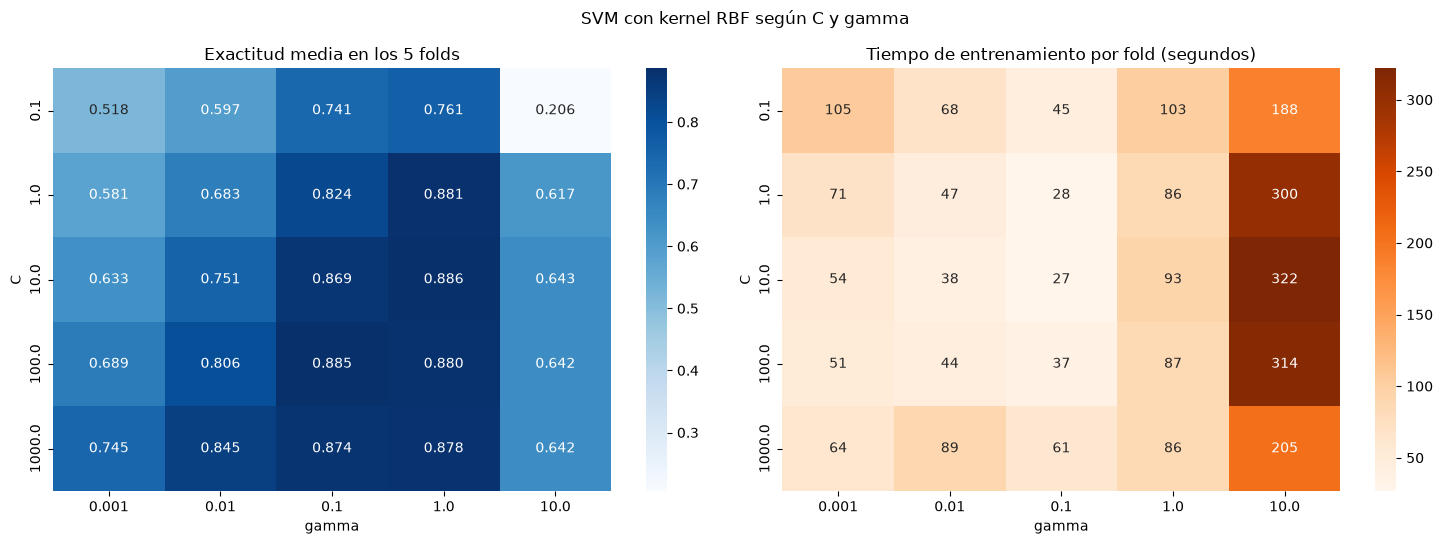

In [21]:
# Exactitud media y tiempo de entrenamiento de cada par de valores de los dos hiperparámetros, con el heatmap de
# seaborn que usamos para las correlaciones. sort=False mantiene el orden de la grilla en filas y columnas
def graficar_interaccion(tabla, filas, columnas, titulo):
    """Mapas de calor de la exactitud media y del tiempo de entrenamiento por fold de cada combinación."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    exactitud = tabla.pivot_table(index=filas, columns=columnas, values="Exactitud media", sort=False)
    sns.heatmap(exactitud, annot=True, fmt=".3f", cmap="Blues", ax=axes[0])
    axes[0].set_title("Exactitud media en los 5 folds")
    tiempo = tabla.pivot_table(index=filas, columns=columnas, values="Entrenamiento por fold (s)", sort=False)
    sns.heatmap(tiempo, annot=True, fmt=".0f", cmap="Oranges", ax=axes[1])
    axes[1].set_title("Tiempo de entrenamiento por fold (segundos)")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


graficar_interaccion(tabla_rbf, "C", "gamma", "SVM con kernel RBF según C y gamma")

Se cumple. El RBF llega a 0,886 de exactitud, contra 0,623 del lineal. La exactitud cae en los dos extremos de gamma: con gamma = 0,001 no pasa de 0,745, y con gamma = 10 se derrumba a entre 0,617 y 0,643 para C de 1 en adelante (0,206 con C = 0,1). Las mejores combinaciones forman una diagonal en el mapa: con gamma = 0,01 el mejor C es 1000 (0,845), con gamma = 0,1 es 100 (0,885) y con gamma = 1 es 10 (0,886). Cuanto mayor es gamma, menor es el C que necesita: los dos controlan la complejidad de la frontera (U5_SVMClassifier_wine.ipynb), y con un gamma mayor la frontera ya es más flexible. El máximo queda dentro de la grilla, así que no hace falta ampliarla.

Con gamma = 0,1 están las combinaciones más rápidas (de 27 a 61 segundos por fold), y con gamma = 10 las más lentas (de 188 a 322), que además son las de peor exactitud.

Con gamma = 10 la precisión se separa mucho de la exactitud: con C = 1, por ejemplo, es 0,8775 contra 0,6172. Eso quiere decir que casi todos los cultivos, cuando el modelo los predice, están bien, y que los errores se juntan en unos pocos cultivos que predice de más. Una explicación posible es que gamma regula la influencia de cada punto (U5_SVMClassifier_wine.ipynb): con gamma = 10 cada fila de entrenamiento influye solo en su entorno inmediato, y la frontera se ajusta a esas filas sin generalizar al fold de evaluación.

### 3.2 Mejor configuración

In [22]:
mejor_rbf = mejor_configuracion(resultados_rbf)
tabla_rbf.loc[[mejor_rbf.name]]

,C,gamma,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
13,10.0,1.0,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,93.2


Elegimos **C = 10 y gamma = 1**, la de mayor exactitud media (0,8864, con un desvío de 0,0035). La segunda, C = 100 y gamma = 0,1, queda a menos de la mitad del desvío (0,8850), así que la diferencia no es firme. Esa combinación varía menos entre folds (desvío de 0,0018) y entrena en 37 segundos por fold en lugar de 93, pero el criterio de 2.1 elige la de mayor exactitud media.

---
## 4. Random Forest

### 4.1 Búsqueda de n_estimators y max_depth

En 1.4, varios grupos de cultivos se separaban con un corte en una sola variable (la temperatura o el pH), que es lo que hace cada nodo de un árbol: esperamos que el Random Forest supere a los dos SVM. También esperamos que la profundidad pese más que la cantidad de árboles, porque un árbol de 5 niveles tiene a lo sumo 32 hojas para 10 cultivos, y que sumar árboles mejore cada vez menos mientras el tiempo crece en proporción.

Probamos 5 valores de `n_estimators` (50, 100, 200, 300 y 500) y 7 de `max_depth` (de 5 a 30, de 5 en 5, y sin límite): 35 combinaciones × 5 folds = 175 entrenamientos. A las profundidades del ejemplo de la consigna (5, 10, 20 y sin límite) les sumamos 15, 25 y 30, para ver dónde se estabiliza la exactitud.

El Random Forest no necesita datos estandarizados (notebook de árboles de clasificación de la U4), pero usamos el mismo pipeline que en los SVM. No cambia los resultados: estandarizar no cambia qué filas quedan de cada lado de un corte.

In [23]:
GRILLA_RF = {"randomforestclassifier__n_estimators": [50, 100, 200, 300, 500],
             "randomforestclassifier__max_depth": [5, 10, 15, 20, 25, 30, None]}
resultados_rf = buscar_hiperparametros(RandomForestClassifier(random_state=SEMILLA), GRILLA_RF)
tabla_rf = tabla_resultados(resultados_rf, {"randomforestclassifier__n_estimators": "n_estimators",
                                            "randomforestclassifier__max_depth": "max_depth"})
# max_depth=None es sin límite de profundidad
tabla_rf["max_depth"] = tabla_rf["max_depth"].fillna("sin límite")

# Ordenada de mayor a menor exactitud media
tabla_rf.sort_values("Exactitud media", ascending=False)

,n_estimators,max_depth,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
29,500,30,0.9162,0.0034,0.9167,0.0034,0.9167,0.0034,88.4
34,500,sin límite,0.9162,0.0035,0.9167,0.0036,0.9167,0.0036,69.8
33,300,sin límite,0.9158,0.0034,0.9164,0.0034,0.9164,0.0034,50.1
28,300,30,0.9157,0.0035,0.9162,0.0035,0.9162,0.0035,53.6
24,500,25,0.9153,0.0036,0.9158,0.0036,0.9158,0.0036,89.2
23,300,25,0.9150,0.0030,0.9156,0.0030,0.9156,0.0030,53.5
32,200,sin límite,0.9150,0.0037,0.9155,0.0037,0.9155,0.0037,35.5
27,200,30,0.9146,0.0034,0.9152,0.0034,0.9152,0.0034,35.5
22,200,25,0.9147,0.0034,0.9152,0.0034,0.9152,0.0034,35.5
31,100,sin límite,0.9143,0.0030,0.9149,0.0031,0.9149,0.0031,17.8


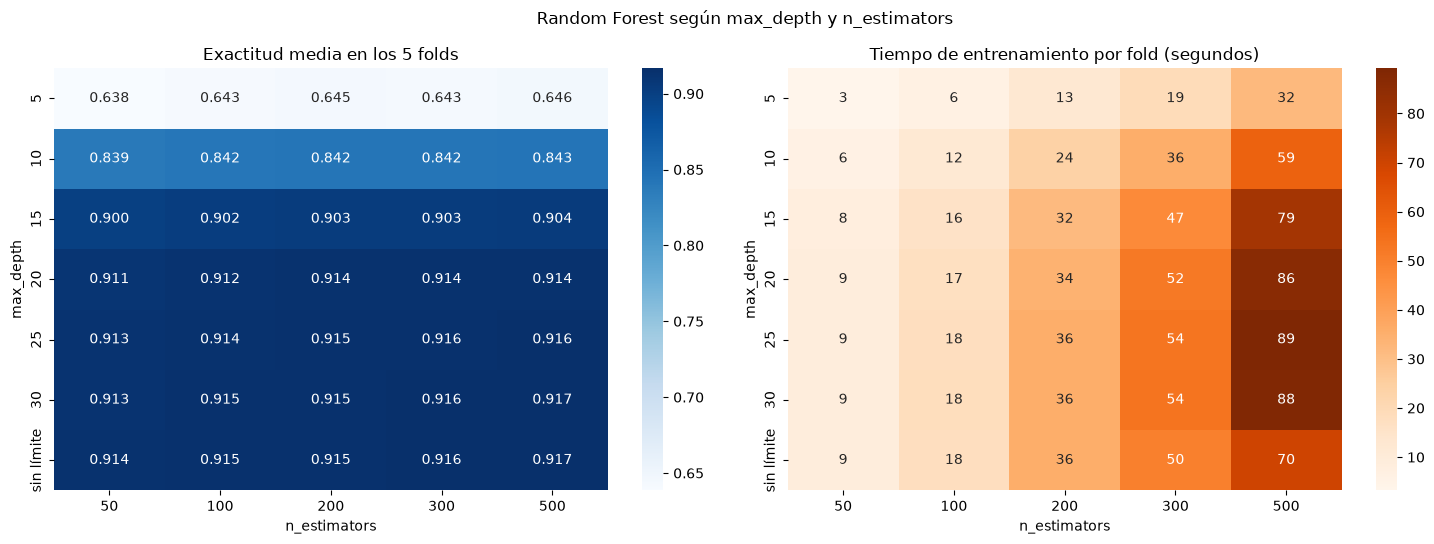

In [24]:
graficar_interaccion(tabla_rf, "max_depth", "n_estimators", "Random Forest según max_depth y n_estimators")

Se cumple. La profundidad es lo que más cambia la exactitud: con `max_depth = 5` no pasa de 0,646, con 10 llega a 0,843, con 15 a 0,904, y desde 25 se estabiliza entre 0,913 y 0,917. Para una misma profundidad, pasar de 50 a 500 árboles mejora menos de 0,01 (sin límite de profundidad, de 0,914 a 0,917), mientras el tiempo crece en proporción: sin límite de profundidad, de 9 a 70 segundos por fold. Todas las combinaciones desde `max_depth = 15` superan al mejor SVM RBF (0,8864).

### 4.2 Mejor configuración

In [25]:
mejor_rf = mejor_configuracion(resultados_rf)
tabla_rf.loc[[mejor_rf.name]]

,n_estimators,max_depth,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
29,500,30,0.9162,0.0034,0.9167,0.0034,0.9167,0.0034,88.4


Elegimos **`n_estimators = 500` y `max_depth = 30`** (exactitud media de 0,9167, con un desvío de 0,0034). Con cuatro decimales empata con 500 árboles sin límite de profundidad, pero no son el mismo bosque: los desvíos son distintos (0,0034 contra 0,0036), así que aciertan distinto en cada fold, y eso quiere decir que el límite de 30 niveles corta algunos árboles. El criterio de 2.1 devuelve `max_depth = 30`. Como en los SVM, las diferencias con las combinaciones que siguen son chicas: 300 árboles sin límite de profundidad quedan a 0,0003 y entrenan en 50 segundos por fold, en lugar de 88.

### 4.3 Importancia de las variables

Analizamos la importancia del bosque elegido, reentrenado con todos los datos limpios. Por 1.4, esperamos que las más importantes sean las temperaturas y el pH. Como `temperatura` y `temp_min_mensual` están muy correlacionadas (0,95, en 1.7), esperamos que se repartan la importancia, porque muchos cortes se pueden hacer con cualquiera de las dos.

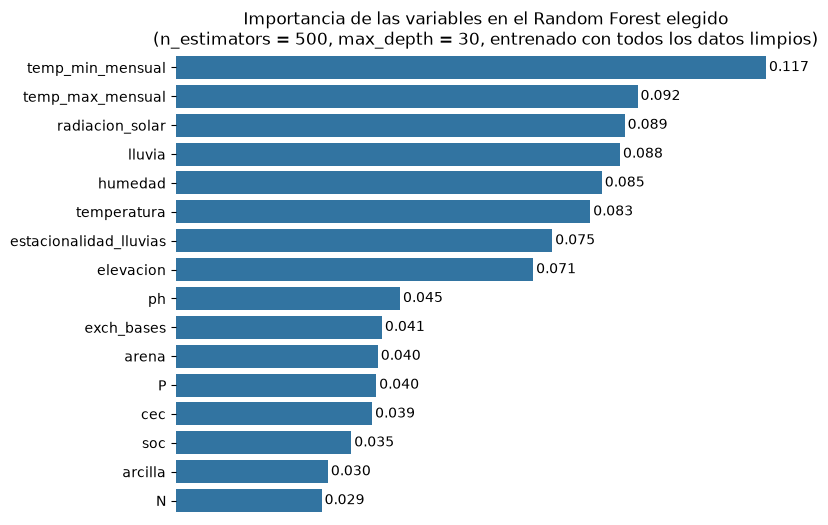

In [26]:
# El bosque con la mejor configuración, reentrenado con los 49803 datos limpios (los 5 folds juntos). n_jobs=-1
# entrena los árboles en paralelo y no cambia el resultado
bosque = crear_modelo(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)).set_params(**mejor_rf["params"])
bosque.fit(X, y)

# Importancia de cada variable, con el gráfico de barras de Ensambles_RandomForest.ipynb (U6, sección "Importancia
# de las características"). bosque[-1] es el último paso del pipeline, el Random Forest
importancias = pd.DataFrame({"variable": ATRIBUTOS, "importancia": bosque[-1].feature_importances_})
importancias = importancias.sort_values(by="importancia", ascending=False)

plt.figure(figsize=(8, 6))
g = sns.barplot(data=importancias, x="importancia", y="variable")
sns.despine(bottom=True, left=True)
g.set_title(f"Importancia de las variables en el Random Forest elegido\n(n_estimators = "
            f"{tabla_rf.loc[mejor_rf.name, 'n_estimators']}, max_depth = {tabla_rf.loc[mejor_rf.name, 'max_depth']}, "
            "entrenado con todos los datos limpios)")
g.set(xlabel=None, ylabel=None, xticks=[])
for barras in g.containers:
    g.bar_label(barras, padding=2, fmt="%.3f")
plt.show()

Se cumple en parte. Las ocho variables más importantes son todas de clima o de ubicación, con importancias de 0,071 a 0,117: las tres temperaturas, la radiación solar, la lluvia, la humedad, la estacionalidad de las lluvias y la elevación. Las ocho del suelo quedan abajo, entre 0,029 y 0,045. El pH es la más importante del suelo (0,045), pero queda novena. Una explicación posible es que la separación entre suelos ácidos y neutros de 1.4 ya la dan las variables de clima, con las que el pH está muy correlacionado (−0,79 con la humedad y −0,78 con la lluvia, en 1.7).

`temperatura` y `temp_min_mensual` se reparten la importancia, como esperábamos: las dos quedan arriba (0,083 y 0,117), y juntas suman 0,200, más del doble que cualquier otra variable.

---
## 5. Comparación de modelos

### 5.1 Métricas de la mejor configuración de cada algoritmo

In [27]:
# La fila de la mejor configuración de cada algoritmo en las tablas de 2, 3 y 4
COLUMNAS = list(tabla_lineal.columns.drop("C"))
comparacion = pd.DataFrame([tabla_lineal.loc[mejor_lineal.name, COLUMNAS],
                            tabla_rbf.loc[mejor_rbf.name, COLUMNAS],
                            tabla_rf.loc[mejor_rf.name, COLUMNAS]],
                           index=["SVM lineal", "SVM RBF", "Random Forest"])
configuracion_rf = tabla_rf.loc[mejor_rf.name]
comparacion.insert(0, "Configuración", [
    f"C = {mejor_lineal['param_svc__C']:g}",
    f"C = {mejor_rbf['param_svc__C']:g}, gamma = {mejor_rbf['param_svc__gamma']:g}",
    f"n_estimators = {configuracion_rf['n_estimators']}, max_depth = {configuracion_rf['max_depth']}"])
comparacion

,Configuración,Precisión media,Precisión desvío,Exhaustividad media,Exhaustividad desvío,Exactitud media,Exactitud desvío,Entrenamiento por fold (s)
SVM lineal,C = 100,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,860.9
SVM RBF,"C = 10, gamma = 1",0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,93.2
Random Forest,"n_estimators = 500, max_depth = 30",0.9162,0.0034,0.9167,0.0034,0.9167,0.0034,88.4


El Random Forest es el mejor en las tres métricas: 0,9167 de exactitud, 0,030 más que el SVM RBF (0,8864) y 0,29 más que el SVM lineal (0,6232). La diferencia con el RBF es casi nueve veces el desvío entre folds, así que, a diferencia de las elecciones dentro de cada modelo, esta sí es firme. Los tres son estables: el desvío entre folds no pasa de 0,005 en ninguno, y los del Random Forest y el RBF son casi iguales (0,0034 y 0,0035).

En tiempo de entrenamiento, el Random Forest (88 segundos por fold) y el RBF (93) están parejos, y el lineal es el más lento (861) por el C = 100 elegido en 2.2: con C = 1, que rinde casi lo mismo, tarda 84 segundos. Estos tiempos se midieron durante las búsquedas, que entrenaban varios modelos a la vez, así que sirven para comparar los modelos entre sí, pero no son los de un modelo entrenado solo.

### 5.2 Matrices de confusión

Usamos el fold 1 (el mismo de 1.8), una de las dos opciones de la consigna, así las matrices salen del mismo esquema que las métricas: cada modelo se entrena con los otros 4 folds y predice unas 1000 filas de cada cultivo.

Por 1.4, esperamos errores en `banana` y `cafe`, que se parecen en casi todas las variables, y en `maiz`, el cultivo con los rangos más amplios. También esperamos que se confundan `garbanzo` y `lenteja`: en los diagramas de 1.4 los dos tienen suelos neutros y poca lluvia, y aunque `lenteja` es mucho más fría, `garbanzo` tiene una cola de temperaturas bajas que llega a sus valores.

In [28]:
# Primer fold de la validación cruzada (el mismo de 1.8): cada modelo se entrena con los otros 4 folds y predice este
X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
y_train, y_test = y[indices_train], y[indices_test]

# La mejor configuración de cada algoritmo
modelos = {"SVM lineal": crear_modelo(SVC(kernel="linear", random_state=SEMILLA)).set_params(**mejor_lineal["params"]),
           "SVM RBF": crear_modelo(SVC(kernel="rbf", random_state=SEMILLA)).set_params(**mejor_rbf["params"]),
           "Random Forest": crear_modelo(RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)).set_params(
               **mejor_rf["params"])}

# Entrenamos cada modelo con los 4 folds de entrenamiento y guardamos sus predicciones sobre el fold 1
predicciones = pd.DataFrame()
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)

for nombre in predicciones:
    print(f"{nombre}: exactitud {accuracy_score(y_test, predicciones[nombre]):.4f} en el fold 1")

SVM lineal: exactitud 0.6182 en el fold 1
SVM RBF: exactitud 0.8888 en el fold 1
Random Forest: exactitud 0.9152 en el fold 1


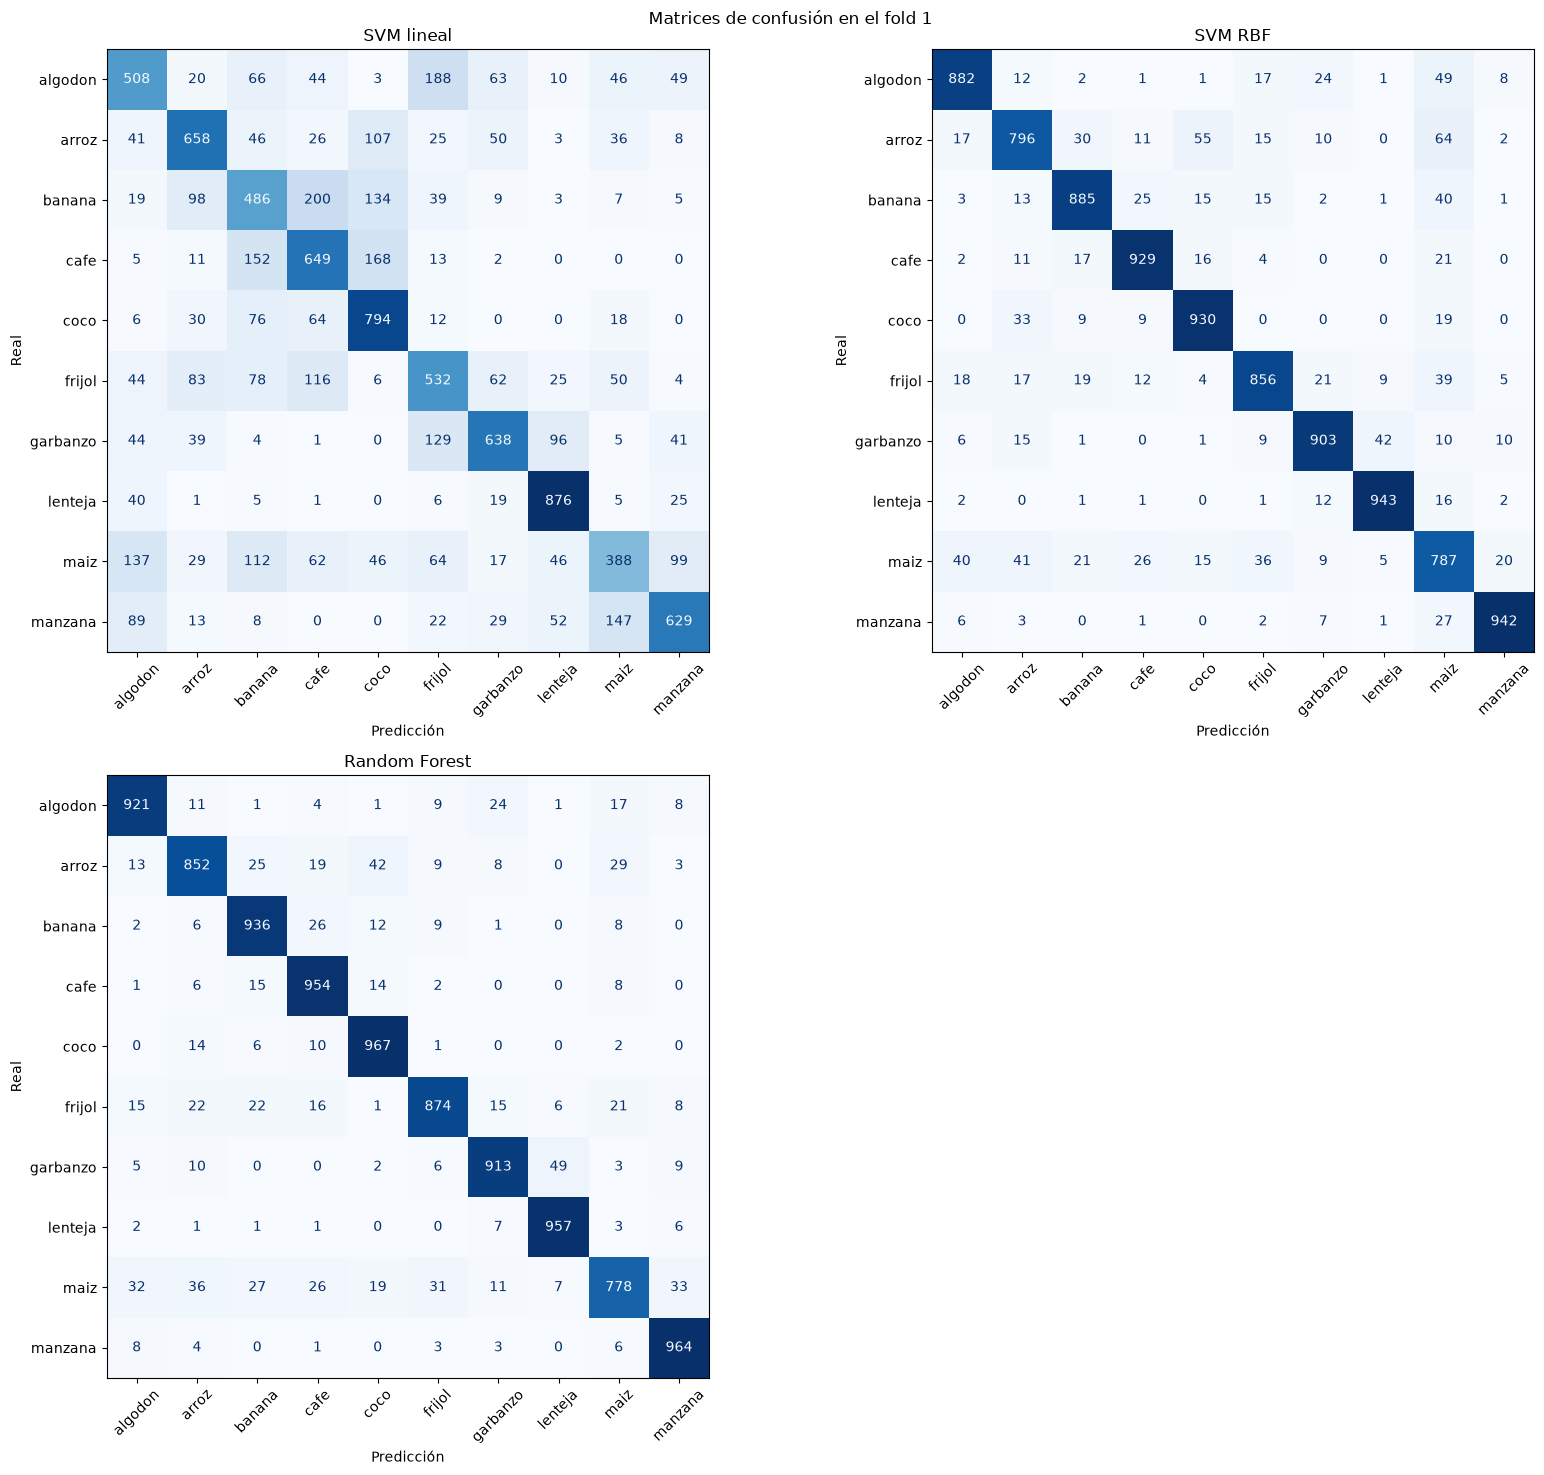

In [29]:
# Adaptado de plot_multiple_conf_matrices de gas_detection.ipynb (U6): la misma grilla de 2 × 2 con una matriz por
# modelo, pero con ConfusionMatrixDisplay (como en el TP2), el mismo mapa de colores para las tres y los nombres de
# los cultivos en los ejes
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
axes = axes.flatten()
for ax, nombre in zip(axes, predicciones):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=codificador.classes_,
                                            cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Real")
fig.delaxes(axes[3])   # sobra el cuarto lugar de la grilla
fig.suptitle("Matrices de confusión en el fold 1")
plt.tight_layout()
plt.show()

Las exactitudes en el fold 1 (0,6182, 0,8888 y 0,9152) están cerca de las medias de los 5 folds de 5.1, así que este fold es representativo.

Se cumple en parte. `maiz` es el cultivo que más les cuesta a los tres modelos, como esperábamos por sus rangos amplios: de sus 1000 filas, el Random Forest acierta 778, el RBF 787 y el lineal 388, y los errores se reparten entre todos los demás cultivos. El RBF, además, predice `maiz` de más: le asigna filas de casi todos los cultivos (64 de `arroz` y 49 de `algodon`, por ejemplo). También se cumple la confusión entre `garbanzo` y `lenteja`: 49 filas de `garbanzo` clasificadas como `lenteja` son el error más frecuente del Random Forest, y en el RBF son 42.

Con `banana` y `cafe`, en cambio, solo se cumple para el lineal: confunde 200 filas de `banana` con `cafe` y 152 de `cafe` con `banana`, mientras que el RBF (25 y 17) y el Random Forest (26 y 15) casi no las confunden. Aunque se parecen en cada variable por separado (1.4), los dos modelos no lineales encuentran combinaciones de variables que las separan. El lineal tiene además otros errores grandes, como 188 filas de `algodon` clasificadas como `frijol`, 168 de `cafe` como `coco` y 147 de `manzana` como `maiz`. Un error que no anticipamos aparece en los dos mejores modelos: `arroz` clasificado como `coco` (55 filas en el RBF y 42 en el Random Forest). En los diagramas de caja de 1.4 son los dos cultivos de menor elevación y están entre los más cálidos, así que comparten buena parte de su rango en esas variables.

### 5.3 Elección del modelo

Elegimos **el Random Forest, con `n_estimators = 500` y `max_depth = 30`**. Es el que mejor clasifica, con una diferencia firme sobre el RBF (5.1), y sus errores están donde los anticipaba el análisis de 1.4. Es tan estable entre folds como el RBF (desvío de 0,0034 contra 0,0035), y su tiempo de entrenamiento es parecido, pero se puede bajar mucho casi sin perder exactitud: con 100 árboles sin límite de profundidad, la exactitud media es 0,9149 y entrena en unos 18 segundos por fold (4.1). Además, es el más fácil de interpretar: la importancia de las variables muestra en qué se apoya la recomendación, sobre todo en el clima (4.3). Los SVM no dan esa información de forma directa, y el apunte de la Unidad 5 («Desventajas de SVM») dice que son difíciles de interpretar, sobre todo con kernels no lineales.

El SVM lineal queda descartado por su exactitud: separar estos cultivos con hiperplanos no alcanza. El RBF es la alternativa más cercana, pero clasifica peor y no permite ver en qué se basa cada recomendación.

---
## 6. Conclusiones

1. El conjunto tenía tres problemas cargados a propósito: una fila con 3 valores faltantes, 198 filas duplicadas (sobre todo de `lenteja` y `manzana`) y 2 filas con valores imposibles (una con un pH de 25, y otra con seis valores imposibles o aislados, entre ellos un pH de 18 y una humedad de 148 %). Las eliminamos y quedaron 49803 filas, con las clases casi balanceadas. Los miles de atípicos que marca la regla del rango intercuartílico en las variables de suelo, la lluvia y la elevación son colas propias de algunos cultivos, y los conservamos.
2. El SVM lineal no alcanza para este problema: su exactitud se estanca en 0,62 desde C = 1, y subir C solo multiplica el tiempo de entrenamiento (de 84 a 861 segundos por fold). Confunde sobre todo cultivos que se parecen en cada variable por separado, como `banana` y `cafe`.
3. El SVM RBF llega a 0,886 de exactitud con C = 10 y gamma = 1. El mejor C depende de gamma: cuanto mayor es gamma, menor es el C que necesita, y con gamma = 10 el modelo se derrumba.
4. El Random Forest, con 500 árboles de hasta 30 niveles, es el mejor modelo: llega a 0,917 de exactitud. La profundidad pesa mucho más que la cantidad de árboles, y las variables de clima pesan más que las del suelo.
5. Dentro de cada modelo, las mejores configuraciones se diferencian menos que el desvío entre folds, y la elección entre ellas no es firme. Entre modelos, en cambio, las diferencias son claras.
6. Elegimos el Random Forest por su exactitud, su estabilidad entre folds, su tiempo de entrenamiento y porque se puede interpretar. Sus errores están donde los anticipó el análisis exploratorio: en `maiz`, el cultivo con los rangos más amplios, y entre `garbanzo` y `lenteja`.